# Homework 3 — Jacobians and Numerical Inverse Kinematics

### Purpose

One of the goals of this course is to:

> **Put the robot arm's end-effector at a commanded position *and* orientation.**

This homework answers the question that follows: given a target pose, **which joint angles get you there?**

To tackle the problem, you should first understand the **Jacobian** — the derivative of the tool pose with respect to the joint angles. Once you have it, inverse kinematics becomes Newton's method.

**Overview.** 

1. **Q1–Q2 Forward kinematics** — where is the tool? You need the current pose to compute its error from the target pose.
2. **Q3 The Jacobian** — how does the tool move when a joint moves?
3. **Q4–Q5 Singularities and redundancy** — when does the Jacobian *fail*, and what does a 7-DoF arm do with its spare degree of freedom?
4. **Q6 Newton-Raphson IK** — put it together and solve for the joint angles.

**Grading:** 100 points.

$\color{red}{\text{Use only numpy, matplotlib and mujoco. MuJoCo is used ONLY to check your work.}}$

### The robot

`ForteArm`: 7 revolute joints, all frames axis-aligned with the base at zero posture (every body
quaternion in the MJCF is the identity), so the whole chain is *translate, then
rotate about one axis*:

| $i$ | joint | axis | offset ${}_{i-1}p_{i}$ [m] | travel |
|---|---|---|---|---|
| 1 | shoulder_yaw | $z$ | (0, 0, 0) | $\pm180^\circ$ |
| 2 | shoulder_pitch | $y$ | (0, 0, 0.177) | $\pm90^\circ$ |
| 3 | shoulder_roll | $x$ | (0, 0, 0) | $\pm90^\circ$ |
| 4 | elbow_pitch | $y$ | (0.43, 0, 0) | $[0, 180^\circ]$ |
| 5 | lower_arm_roll | $x$ | (0, 0, 0.035) | $\pm180^\circ$ |
| 6 | wrist_pitch | $y$ | (0.447, 0, 0) | $\pm90^\circ$ |
| 7 | wrist_roll | $x$ | (0.087, 0, 0) | $\pm180^\circ$ |
| tool | `ee_tip` | — | (0.04, 0, 0) | |

**Frame convention.** ${}_{i-1}T_{i}$ is frame $\{i\}$ *expressed in* frame
$\{i\!-\!1\}$ — the **left** subscript names the reference frame, the right subscript
the frame being described — and likewise for its parts ${}_{i-1}R_{i}$ and
${}_{i-1}p_{i}$. Composition cancels the inner index:
${}_{0}T_{2} = {}_{0}T_{1}\,{}_{1}T_{2}$.

**Sign convention.** The pitch joints rotate about $+y$, so by the right-hand rule
a **positive** angle swings the link **downward**. Hence negative `shoulder_pitch`
lifts the arm, and `elbow_pitch` is $0$ when fully stretched and **positive** as the
forearm folds in.

**Range of motion.** Because the pitch joints do **not** span a full revolution, $q + 2\pi$ can be outside the joint range even when $q$ is a valid IK solution. An IK solver therefore cannot simply wrap angles — it has to project back into the box.

**Twist convention.** Throughout this homework a 6-vector is
$\mathcal{V} = [\,\omega\,;\,v\,]$ — **angular part first**, which is the order the adjoint formula in Q3 assumes. Other references may stack it the other way, $[\,v\,;\,\omega\,]$, and MuJoCo hands the two blocks back separately. Mixing them up is the most common bug in this assignment.

In [ ]:
# No need to change
import numpy as np
import matplotlib.pyplot as plt
import mujoco

np.set_printoptions(precision=6, suppress=True)

OFF = np.array([[0, 0, 0], [0, 0, 0.177], [0, 0, 0], [0.43, 0, 0],
                [0.0, 0, 0.035], [0.447, 0, 0], [0.087, 0, 0]], float)
AXIS = np.array([[0,0,1], [0,1,0], [1,0,0], [0,1,0], [1,0,0], [0,1,0], [1,0,0]], float)

EE_OFF = np.array([0.04, 0.0, 0.0])
N_JOINTS = 7

# --- MuJoCo, used ONLY as ground truth to check your implementation ---
MODEL = "../ForteArm_Model/forte_scene.xml"
_m = mujoco.MjModel.from_xml_path(MODEL)
_d = mujoco.MjData(_m)
_EE = mujoco.mj_name2id(_m, mujoco.mjtObj.mjOBJ_SITE, "ee_tip")

def mj_fk(q):
    """Ground-truth tool pose from MuJoCo."""
    _d.qpos[:] = q; mujoco.mj_forward(_m, _d)
    T = np.eye(4); T[:3,:3] = _d.site_xmat[_EE].reshape(3,3); T[:3,3] = _d.site_xpos[_EE]
    return T

def mj_jacobian(q):
    """Ground-truth WORLD Jacobian from MuJoCo, ordered [omega; v]."""
    _d.qpos[:] = q; mujoco.mj_forward(_m, _d)
    Jp = np.zeros((3, N_JOINTS)); Jr = np.zeros((3, N_JOINTS))
    mujoco.mj_jacSite(_m, _d, Jp, Jr, _EE)
    return np.vstack([Jr, Jp])

def check(name, got, want, tol=1e-8):
    ok = np.allclose(np.asarray(got, float), np.asarray(want, float), atol=tol)
    print(f'{"PASS" if ok else "FAIL"}  {name}')
    if not ok:
        print('   yours   :', np.asarray(got)); print('   expected:', np.asarray(want))
    return ok

Q_LO = _m.jnt_range[:, 0].copy()      # joint travel limits, straight from the MJCF
Q_HI = _m.jnt_range[:, 1].copy()
Q_READY = _m.key_qpos[1].copy()       # `ready_pose`: well-conditioned, tool well clear of the floor

TARGET_Z_MIN = 0.5                    # the arm is floor-mounted; only ask it for poses it
                                      # could actually be sent to in a workcell

def sample_target(rng, z_min=TARGET_Z_MIN):
    '''A reachable target pose whose tool height is at least z_min.

    Drawn by running FK on a random in-limits configuration and rejecting the
    ones that end up too low -- so every target is reachable by construction.
    Roughly 3 draws per accepted target.
    '''
    while True:
        T = fk(rng.uniform(Q_LO, Q_HI))
        if T[2, 3] >= z_min:
            return T

print('model loaded:', MODEL, '| nq =', _m.nq)
print('joint limits [rad]:'); print('  lo', Q_LO); print('  hi', Q_HI)
print('Q_READY =', Q_READY)

### The same table, drawn

Frame $\{i\}$ sits at ${}_{i-1}p_{i}$ = `OFF[i]` from frame $\{i\!-\!1\}$, and joint $i$
turns about `AXIS[i]` (red). The labels carry the true offsets. Two of them are zero, so $\{1\}$ sits exactly on $\{base \}$ and
$\{3\}$ exactly on $\{2\}$; they are drawn apart only so both are visible.

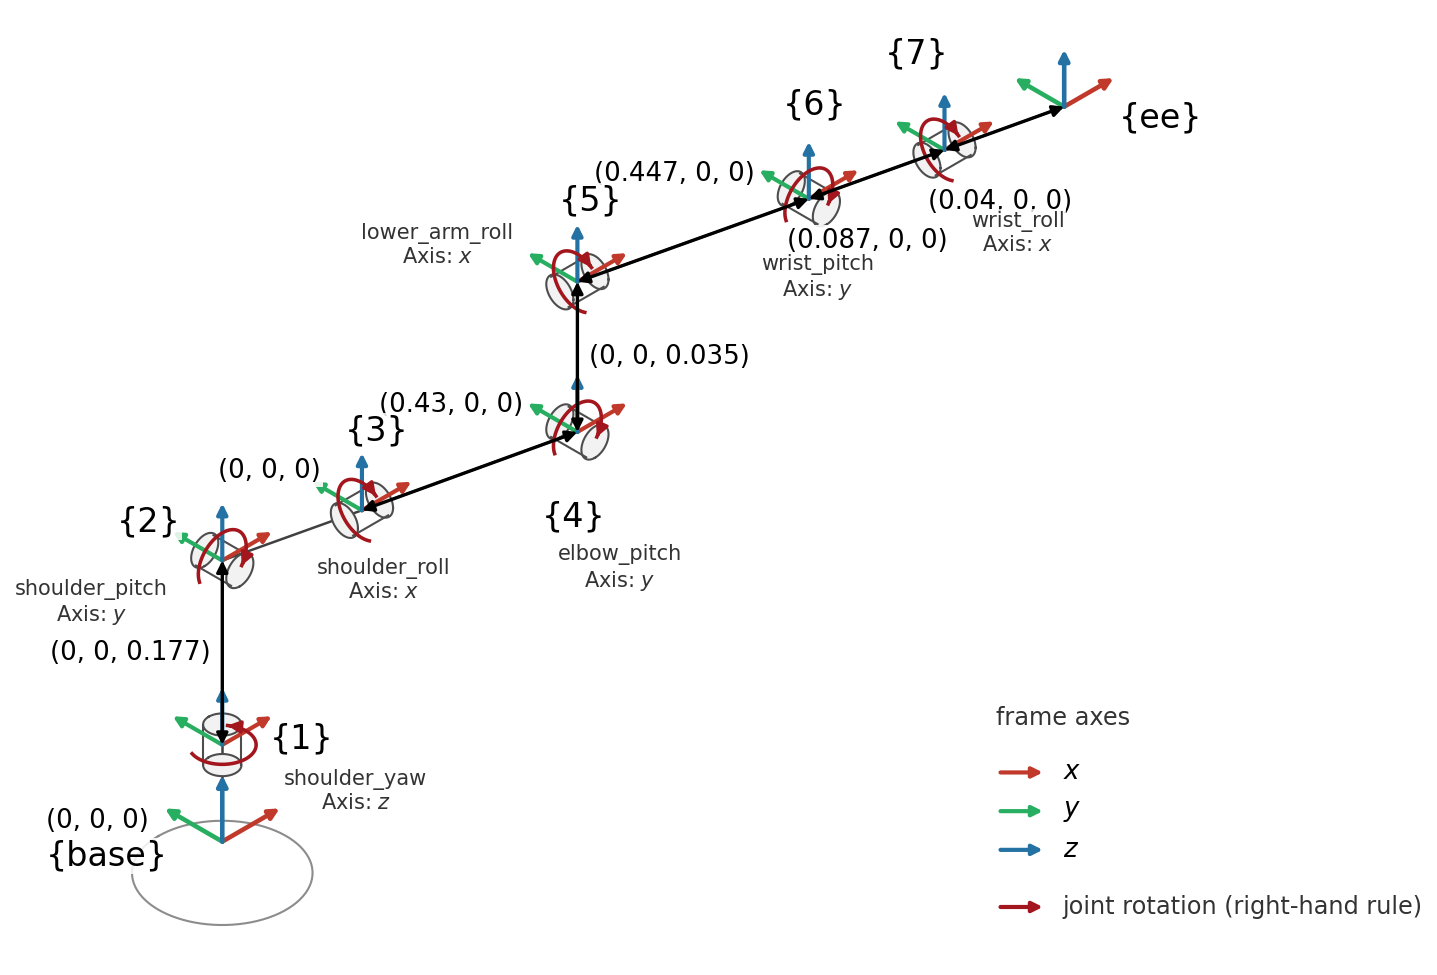

---
# Q1 [12 pts] Forward kinematics

Build the transform from the base to the tool as a product of the per-joint
transforms. Each joint contributes a translation by its offset followed by a
rotation about its own axis:

$${}_{i-1}T_{i}(q_i) = \operatorname{Trans}({}_{i-1}p_{i})\,\operatorname{Rot}(\hat a_i, q_i),
\qquad
{}_{0}T_{\text{tool}}(q) = \Big(\prod_{i=1}^{7} {}_{i-1}T_{i}(q_i)\Big)\ \operatorname{Trans}({}_{7}p_{\text{tool}})$$

**(a)** Complete `rot_axis`, `SE3`, and `link_transforms`. `link_transforms`
returns a dict `T` where `T[i]` is ${}_{i}T_{\text{tool}}$ — **the tool frame
expressed in frame $\{i\}$** — so `T[0]` is ${}_{0}T_{\text{tool}}$, base to tool. You will need exactly this indexing again in Q3.

**(b)** `fk(q)` should then be one line. The self-test compares against MuJoCo at
500 random configurations — you should match to ~1e-15, not "close enough".

In [ ]:
def hat(a):
    '''3-vector -> skew-symmetric matrix.'''
    a = np.asarray(a, float)
    return np.array([[0, -a[2], a[1]], [a[2], 0, -a[0]], [-a[1], a[0], 0]])

def log_SO3(Rm):
    '''Rotation matrix -> axis*angle 3-vector (robust at theta = pi).'''
    c = np.clip((np.trace(Rm) - 1) / 2.0, -1.0, 1.0)
    if c > 1 - 1e-12:
        return np.zeros(3)
    if c < -1 + 1e-12:
        A = Rm + np.eye(3); k = int(np.argmax(np.linalg.norm(A, axis=0)))
        return np.pi * A[:, k] / np.linalg.norm(A[:, k])
    th = np.arccos(c); S = (Rm - Rm.T) / (2 * np.sin(th))
    return th * np.array([S[2,1], S[0,2], S[1,0]])

def rot_axis(axis, theta):
    '''Rotation matrix for `theta` radians about a unit `axis` (Rodrigues' formula).'''
    # TODO Q1: Rodrigues. R = I + sin(t)K + (1-cos(t))K^2, K = hat(unit axis).
    raise NotImplementedError("Q1: rot_axis")

def SE3(Rm, p):
    '''Pack a rotation and a translation into a 4x4 homogeneous transform.'''
    # TODO Q1: pack R and p into a 4x4 homogeneous transform.
    raise NotImplementedError("Q1: SE3")

def link_transforms(q):
    '''Return dict T with T[i] = transform from frame i to the TOOL frame.

    T[7] is frame7 -> tool (a pure translation by EE_OFF), and T[0] is base -> tool.
    '''
    # TODO Q1: build each frame i-1 -> i transform (translate by OFF[i],
    #          then rotate about AXIS[i] by q[i]), then accumulate BACKWARDS
    #          so that T[i] is the transform from frame i to the TOOL.
    raise NotImplementedError("Q1: link_transforms")

def fk(q):
    '''Base -> tool transform.'''
    # TODO Q1: which entry of link_transforms(q) is base -> tool?
    raise NotImplementedError("Q1: fk")


In [ ]:
# --- self test: your FK vs MuJoCo, 500 random configurations ---
rng = np.random.default_rng(0)
worst = 0.0
for _ in range(500):
    q = rng.uniform(Q_LO, Q_HI)
    worst = max(worst, np.abs(fk(q) - mj_fk(q)).max())
print(f'max |FK - MuJoCo| over 500 configs = {worst:.3e}')
check('Q1 forward kinematics', worst, 0.0, tol=1e-10)
print()
print('tool pose at Q_READY:'); print(fk(Q_READY))

### Seeing it

A number like `...e-16` says your FK agrees with MuJoCo. Let's render the configurations you just
tested — your FK produced the pose, MuJoCo drew it, and if the two disagreed you
would see the tool marker in the wrong place.

(Rendering is *given* and is not required to answer any question. On Linux without a
display, set `MUJOCO_GL=egl`; do not worry if it still will not cooperate. The numeric
checks above are sufficient for grading.)

In [ ]:
import sys; sys.path.append('..')
from forte_viz import ForteViz, show_video, show_filmstrip

viz = ForteViz(width=960, height=704)     # render size; raise it if you want more detail

# the first four of the 500 random configurations the FK test just used
rng_v = np.random.default_rng(0)
q_samples = [rng_v.uniform(Q_LO, Q_HI) for _ in range(4)]
show_filmstrip([viz.frame(q) for q in q_samples], n=4, cols=2,
               title='four random configurations (yellow ball = ee_tip, the frame your FK computes)')

---
# Q2 [8 pts] Reachable workspace

Before asking for a target pose it is worth knowing which targets are even possible.

**(a)** Sample 5000 random joint configurations, run your FK, and scatter-plot the
tool positions in the $x$–$z$ plane and the $x$–$y$ plane.

**(b)** Report the maximum reach $\max\|p\|$ and the minimum $\min\|p\|$. Compare
the maximum against the sum of the link offsets in the table — should they be
equal? Explain any difference in 1–2 sentences.

This plot is also how you tell an unreachable request apart from a solver failure
later on: if a target lies outside this cloud, no IK method will find it, and the
fault is in the target, not in your IK solver.

In [ ]:
# === HW SOLUTION START: q2.workspace ===
rng = np.random.default_rng(1)
P = np.array([fk(rng.uniform(Q_LO, Q_HI))[:3, 3] for _ in range(5000)])
# === HW SOLUTION END: q2.workspace ===

r = np.linalg.norm(P, axis=1)
print(f'max reach {r.max():.4f} m   min reach {r.min():.4f} m')
print(f'sum of link offsets = {np.linalg.norm(OFF, axis=1).sum() + np.linalg.norm(EE_OFF):.4f} m')

fig, ax = plt.subplots(1, 2, figsize=(11, 5))
ax[0].scatter(P[:,0], P[:,2], s=1, alpha=0.15); ax[0].set_xlabel('x [m]'); ax[0].set_ylabel('z [m]')
ax[1].scatter(P[:,0], P[:,1], s=1, alpha=0.15); ax[1].set_xlabel('x [m]'); ax[1].set_ylabel('y [m]')
for a_ in ax: a_.set_aspect('equal'); a_.grid(alpha=0.3)
ax[0].set_title('workspace, x-z'); ax[1].set_title('workspace, x-y')
plt.tight_layout(); plt.show()

**(Your answer for Q2b)**

*write here*

---
# Q3 [26 pts] The Jacobian, via the adjoint

The Jacobian maps joint rates to the tool twist: $\mathcal{V} = J(q)\,\dot q$,
with $\mathcal{V} = [\omega; v] \in \mathbb{R}^6$ and $J \in \mathbb{R}^{6\times 7}$.

Joint $i$ produces, *in its own frame*, the unit twist
$\mathcal{S}_i = [\hat a_i;\ 0]$ — pure rotation about its axis through its own
origin. To assemble the Jacobian you move each of those twists into a common
frame using the **adjoint**:

$$\operatorname{Ad}_{T} = \begin{bmatrix} R & 0 \\ [p]_\times R & R \end{bmatrix},
\qquad T = \begin{bmatrix} R & p \\ 0 & 1\end{bmatrix}$$

Expressing every joint twist in the **tool** frame gives the **body Jacobian**:

$$J_b(:,i) = \operatorname{Ad}_{({}_{i}T_{\text{tool}})^{-1}}\ \mathcal{S}_i$$

Rotating those columns into world orientation (keeping the tool as the reference
point) gives the **world Jacobian** used for Cartesian control:

$$J_w = \operatorname{Ad}_{({}_{0}R_{\text{tool}},\,0)}\ J_b$$

**(a)** Complete `Adj` and `jacobian`.

**(b)** Verify against MuJoCo's `mj_jacSite` (world frame) at 500 random configs.

**(c)** In 2–3 sentences: why is $J$ here $6\times 7$ and not $6\times 6$, and what
does that extra column mean physically? 

In [ ]:
def Adj(T):
    '''6x6 adjoint of a homogeneous transform, for twists ordered [omega; v].'''
    # TODO Q3: 6x6 adjoint for twists ordered [omega; v].
    #          Top-left R, bottom-right R, bottom-left [p]x R, top-right 0.
    raise NotImplementedError("Q3: Adj")

def jacobian(q, frame='world'):
    '''6x7 tool Jacobian. frame='body' -> expressed in the tool frame,
       frame='world' -> rotated into world orientation.'''
    T = link_transforms(q)
    # TODO Q3: for each joint, write its unit twist in its OWN frame, then use
    #          the adjoint to express it in the tool frame -> body Jacobian.
    #          For frame='world', rotate those columns into world orientation
    #          (rotation only -- the reference point stays the tool).
    raise NotImplementedError("Q3: jacobian")


In [ ]:
# --- self test: world Jacobian vs MuJoCo, and body vs world consistency ---
rng = np.random.default_rng(2)
worst_w = worst_b = 0.0
for _ in range(500):
    q = rng.uniform(Q_LO, Q_HI)
    worst_w = max(worst_w, np.abs(jacobian(q, 'world') - mj_jacobian(q)).max())
    Rm = fk(q)[:3, :3]
    Jw = mj_jacobian(q)
    Jb_truth = np.vstack([Rm.T @ Jw[:3], Rm.T @ Jw[3:]])
    worst_b = max(worst_b, np.abs(jacobian(q, 'body') - Jb_truth).max())
print(f'max |J_world - MuJoCo| = {worst_w:.3e}')
print(f'max |J_body  - MuJoCo| = {worst_b:.3e}')
check('Q3 world Jacobian', worst_w, 0.0, tol=1e-10)
check('Q3 body  Jacobian', worst_b, 0.0, tol=1e-10)
print(f'\nJ shape = {jacobian(Q_READY).shape}')

**(Your answer for Q3c)**

*write here*

---
# Q4 [12 pts] Singularities and conditioning

Newton's method inverts the Jacobian. Where $J$ loses rank, that inverse blows up —
and the arm physically cannot move the tool in some direction, no matter what the
joints do. The singular values of $J$ tell you how close you are.

**(a)** Compute the singular values of the world Jacobian at `q = 0` (`init_pose`)
and at `Q_READY`. Report $\sigma_{\min}$ and the condition number
$\sigma_{\max}/\sigma_{\min}$ for each.

**(b)** At `q = 0` the arm is stretched straight out along $x$. $\sigma_{\min}$ is
tiny there. Take the left-singular vector belonging to $\sigma_{\min}$ — that is
the tool twist direction the arm is nearly unable to produce. Print it and say in
words which motion is (nearly) lost, and why that makes geometric sense for a
straight arm.

**(c)** Newton's method needs an initial guess. Based on (a) and (b), would you start
the IK solver from `init_pose` or from `ready_pose`? Justify your choice in 2–3
sentences. 

In [ ]:
for name, qq in [('init_pose (q=0)', np.zeros(N_JOINTS)), ('ready_pose', Q_READY)]:
    # === HW SOLUTION START: q4.svd ===
    U, S, Vt = np.linalg.svd(jacobian(qq, 'world'))
    # === HW SOLUTION END: q4.svd ===
    print(f'{name:18s} sigma = {S}')
    print(f'{"":18s} sigma_min = {S.min():.5f}   cond = {S.max()/S.min():8.1f}')

U, S, Vt = np.linalg.svd(jacobian(np.zeros(N_JOINTS), 'world'))
print()
print('least-controllable tool twist at q=0 (omega | v):')
print(f'   omega = {U[:3, -1]}')
print(f'   v     = {U[3:, -1]}')

**(Your answer for Q4b and Q4c)**

*write here*

---
# Q5 [10 pts] Redundancy: the seventh joint

$J$ is $6\times 7$ with rank 6, so its **null space is one-dimensional**: there is a
whole direction of joint motion that moves *no* part of the tool pose. This is what
"redundant" means, and it is the degree of freedom a controller can use to shape the
arm's posture while the tool holds its commanded pose.

**(a)** Find a unit null-space vector $\overrightarrow{n}$ with $J \overrightarrow{n} = 0$ (the last right-singular
vector). Verify $\|J\overrightarrow{n}\| \approx 0$.

**(b)** Integrate along it: starting from `Q_READY`, take 200 small steps
$q \leftarrow q + 0.01\,\overrightarrow{n}(q)$, recomputing $\overrightarrow{n}$ each step. **Watch the sign** — an
SVD gives singular vectors only up to sign, so $\overrightarrow{n}$ can flip between steps and the
walk stalls; keep the sign that continues the previous step. Clip to the joint
box as you go. Plot the tool position
error $\|p(q) - p(q_0)\|$ and the tool orientation error against step number. Both
should stay near zero while the joints move substantially — print
$\|q_{200} - q_0\|$ to show they really did move.

(You will see a small residual drift (~mm) rather than exactly zero. That is Euler integration error: $\overrightarrow{n}(q)$ is null only **instantaneously**, so stepping a finite distance along it leaves the null space slightly. Shrink the step size and the drift shrinks with it.)

In [ ]:
def null_space_dir(q):
    '''Unit vector n with J(q) n = 0.'''
    # TODO Q5: the null-space direction is the right-singular vector belonging
    #          to the smallest singular value. Which row of Vt is that?
    raise NotImplementedError("Q5: null_space_dir")

n0 = null_space_dir(Q_READY)
print('null-space direction :', n0)
print('||J n||              :', np.linalg.norm(jacobian(Q_READY, 'world') @ n0))
check('Q5 J n = 0', jacobian(Q_READY, 'world') @ n0, np.zeros(6), tol=1e-9)

# === HW SOLUTION START: q5.integrate ===
q = Q_READY.copy(); T0 = fk(q)
pos_e, ori_e = [], []
prev = null_space_dir(q)
for k in range(200):
    n = null_space_dir(q)
    # An SVD returns singular vectors only up to sign, so n can flip from one
    # step to the next. Walking along a direction that keeps reversing gets you
    # nowhere -- pick the sign that continues the previous step.
    if np.dot(n, prev) < 0:
        n = -n
    prev = n
    q = np.clip(q + 0.01 * n, Q_LO, Q_HI)
    T = fk(q)
    pos_e.append(np.linalg.norm(T[:3,3] - T0[:3,3]))
    ori_e.append(np.linalg.norm(log_SO3(T[:3,:3] @ T0[:3,:3].T)))
# === HW SOLUTION END: q5.integrate ===

print()
print(f'joints moved by ||q200 - q0|| = {np.linalg.norm(q - Q_READY):.4f} rad')
print(f'tool moved by  {pos_e[-1]*1000:.4f} mm  and  {ori_e[-1]:.2e} rad')
plt.figure(figsize=(7,4))
plt.plot(pos_e, label='tool position error [m]')
plt.plot(ori_e, label='tool orientation error [rad]')
plt.xlabel('null-space step'); plt.legend(); plt.grid(alpha=0.3)
plt.title('moving in the null space does not move the tool'); plt.show()

---
# Q6 [32 pts] Newton-Raphson inverse kinematics

Now solve the IK problem. Given a desired tool pose $T_{des}$, iterate

$$e = \begin{bmatrix}\log(R_{des}R^{\top})^{\vee} \\ p_{des}-p\end{bmatrix},
\qquad
\Delta q = J^{\top}\big(JJ^{\top} + \lambda^{2} I\big)^{-1} e,
\qquad q \leftarrow \Pi_{[q_{lo},q_{hi}]}\big(q + \alpha\,\Delta q\big)$$

That middle step is the **damped least-squares** (Levenberg–Marquardt) pseudo-inverse.
For a redundant arm $J^{+} = J^{\top}(JJ^{\top})^{-1}$ is the minimum-norm solution;
the $\lambda^2 I$ keeps it finite near the singularities you found in Q4. The
$\Pi$ is a projection back into the joint box — this arm's shoulder, elbow and
wrist pitch **cannot** turn all the way round, so a solution outside the box is not
a solution.

#### The step size $\alpha$, and why it is there

$J(q)$ is a **derivative**: it describes how the tool moves for an *infinitesimal*
joint motion, and it is only accurate in a neighbourhood of the $q$ where you
evaluated it. The linear model degrades as the step grows.

$\Delta q = J^{+}e$ is the step that would zero the error **if the arm were linear**.
It is not. When $e$ is large, $\Delta q$ is large, and the step lands somewhere the
linearisation never described — possibly with a *larger* error than you started
with. Taking $\alpha\,\Delta q$ for some $0 < \alpha \le 1$ keeps the step inside the
region where $J$ is still a good model of the arm. This is the same idea as a
learning rate, and the same idea as the $\lambda$ damping, applied to a different
failure: $\lambda$ protects you from an ill-conditioned $J$, $\alpha$ protects you
from a $J$ that is well-conditioned but only valid locally.

However, shrinking $\alpha$ comes at a cost. A smaller step is more trustworthy but covers less ground, so
convergence takes more iterations — and a full Newton step is what produces the
quadratic convergence in part (b), so damping every step uniformly *throws that
away*. Part (d) asks you to find the trade-off by measuring it.

**(a)** Complete `pose_error_world` and `ik_world`.

**(b)** Solve for a random reachable target starting from `Q_READY`, with
$\alpha = 1$. Plot $\|e\|$ on a **log** scale against iteration — you should see the
flat-then-cliff shape of quadratic convergence, reaching ~$10^{-11}$ in a dozen or
so iterations.

The cell skips targets that a single run from `Q_READY` cannot reach, and reports
how many it skipped. This is the phenomenon that part (d) is about.

**(c)** Frame consistency: the body Jacobian — see the cell after the animation.

**(d)** Benchmark and failure analysis — see the cell after (c).


In [ ]:
def pose_error_world(T_cur, T_des):
    '''6-D world-frame pose error, ordered [omega; v] to match the Jacobian.'''
    # TODO Q6: 6-D pose error ordered [omega; v] to match the Jacobian.
    #          Orientation goes through log_SO3; position subtracts.
    raise NotImplementedError("Q6: pose_error_world")

def ik_world(q0, T_des, iters=300, lam=1e-2, tol=1e-10, step=1.0, dq_max=None):
    '''Damped least-squares Newton-Raphson IK, respecting the joint box.

    step   : the step size alpha. 1.0 is the full Newton step.
    dq_max : optional trust region -- if given, rescale any step longer than
             dq_max radians down to dq_max, leaving shorter steps untouched.
    Returns (q, history of ||e||).
    '''
    q = np.clip(np.asarray(q0, float).copy(), Q_LO, Q_HI)
    hist = []
    for k in range(iters):
        # TODO Q6: one Newton iteration. Compute e, record ||e||, break on tol,
        #          build J, solve the damped least-squares step, scale it by `step`,
        #          apply the dq_max trust region if one was given, then update q
        #          and PROJECT back into [Q_LO, Q_HI].
        raise NotImplementedError("Q6: ik_world")
    return q, hist

In [ ]:
# (b) one problem, convergence curve.
# NOTE: a single Newton run from Q_READY does NOT solve every target -- part (d)
# measures exactly how often it fails. So for this plot we draw targets until we
# find one that Q_READY can reach in one shot, and count how many we had to skip.
rng = np.random.default_rng(5)
q0 = Q_READY.copy()
skipped = 0
while True:
    T_des = sample_target(rng)
    q_sol, hist = ik_world(q0, T_des)
    if hist[-1] < 1e-8:
        break
    skipped += 1
print(f'skipped {skipped} target(s) that one shot from Q_READY could not reach')
print(f'converged in {len(hist)} iterations, final ||e|| = {hist[-1]:.3e}')
check('Q6 IK reached the target', hist[-1], 0.0, tol=1e-8)

plt.figure(figsize=(7,4))
plt.semilogy(hist, 'o-')
plt.xlabel('iteration'); plt.ylabel(r'$\|e\|$'); plt.grid(alpha=0.3, which='both')
plt.title('Newton-Raphson IK: quadratic convergence'); plt.show()

### Watch it converge

The log-scale plot shows the error collapsing. This shows what the arm is doing
while it collapses.

Note the step size below: this animation runs at $\alpha = 0.3$, not the
$\alpha = 1$ used for the convergence plot above. That is deliberate, and it is
worth trying both. At $\alpha = 1$ Newton's method does not move along a
sensible-looking path — it takes whatever joint step the linearised model says is
best, and early on that swings the arm through a wild intermediate posture before
it settles. Damping the step keeps the arm near configurations where the Jacobian
was actually valid, and the motion looks far more like something you would be
willing to run on hardware. Set `step=1.0` and re-render to see the difference.

The RGB frame is the commanded target pose; the yellow ball is the tool.

In [ ]:
# re-run the same IK problem, keeping every intermediate configuration
def ik_world_history(q0, T_des, iters=200, lam=1e-2, tol=1e-10, step=0.3):
    '''Same solver as ik_world, but returns every intermediate q for rendering.
       step=0.3 by default -- try step=1.0 to see the undamped Newton path.'''
    q = np.asarray(q0, float).copy(); qs = [q.copy()]
    for k in range(iters):
        e = pose_error_world(fk(q), T_des)
        if np.linalg.norm(e) < tol: break
        J = jacobian(q, 'world')
        q = q + step * (J.T @ np.linalg.solve(J @ J.T + lam**2*np.eye(6), e))
        qs.append(q.copy())
    return qs

qs = ik_world_history(q0, T_des)
target = (T_des[:3, 3], T_des[:3, :3])
frames = viz.render_configs(qs, target=target, hold_last=8, zoom=1.4)
print(f'{len(qs)} IK iterations at step=0.3')
show_filmstrip(frames, n=6, cols=3, title='Newton-Raphson IK: initial guess -> target')

In [ ]:
# and as a video
show_video(frames, fps=6, path='ik_convergence.mp4', width=720)

### Q6(c) — Frame consistency: the body Jacobian

`ik_world` pairs the **world** Jacobian with an error expressed in **world**
orientation. Q3 also gave you the **body** Jacobian $J_b$, the same derivative
expressed in the tool frame. Either one can drive Newton's method, but the error has
to be expressed in the **same** frame as the Jacobian. The tool-frame (body) error is

$$e_b = \begin{bmatrix}\log(R^{\top}R_{des})^{\vee} \\ R^{\top}(p_{des}-p)\end{bmatrix}.$$

Complete `pose_error_body`. The cell then solves with all four pairings of Jacobian
and error: first on the target from (b), then on 100 random targets at $\alpha = 0.4$.
Every pairing is scored on the same world error, so the rows are comparable.

**Answer these:**

1. The two consistent pairings (world/world and body/body) produce **exactly the same**
   joint steps — the cell shows their iterates differ only by floating-point rounding
   (~1e-11). Show why: express $e_b$ and $J_b$ in terms of $e_w$ and $J_w$ using
   $B = \operatorname{diag}(R^{\top}, R^{\top})$, substitute them into the damped
   least-squares step, and show that $B$ cancels. *Hint:* $B$ is a rotation, so
   $BB^{\top} = I$.
2. The mixed pairings almost never converge, even with a damped step. Near the
   solution, what world-frame motion does the mixed step $J_b^{+}e_w$ actually command,
   compared with what $e_w$ asks for? Use that to explain why the failure depends on
   how far the target orientation is rotated from the base frame.


In [ ]:
def pose_error_body(T_cur, T_des):
    '''6-D pose error expressed in the TOOL frame, ordered [omega; v].'''
    # TODO Q6c: the same 6-D pose error, expressed in the TOOL frame.
    #           Orientation: log_SO3 of R^T R_des. Position: rotate the world
    #           difference into the tool frame.
    raise NotImplementedError("Q6c: pose_error_body")

def ik_pair(q0, T_des, jac_frame, err_fn, iters=300, lam=1e-2, tol=1e-10, step=1.0):
    '''The ik_world loop with the Jacobian frame and the error chosen independently.
       Progress is always measured with the WORLD error, so all pairings are scored alike.
       Returns (list of iterates, history of ||e_world||).'''
    q = np.clip(np.asarray(q0, float).copy(), Q_LO, Q_HI)
    qs, hist = [], []
    for k in range(iters):
        T = fk(q)
        hist.append(np.linalg.norm(pose_error_world(T, T_des)))
        if hist[-1] < tol:
            break
        J = jacobian(q, jac_frame)
        e = err_fn(T, T_des)
        q = np.clip(q + step * (J.T @ np.linalg.solve(J @ J.T + lam**2 * np.eye(6), e)), Q_LO, Q_HI)
        qs.append(q.copy())
    return qs, hist

PAIRS = [('J_world + e_world', 'world', pose_error_world),
         ('J_body  + e_body ', 'body',  pose_error_body),
         ('J_body  + e_world', 'body',  pose_error_world),
         ('J_world + e_body ', 'world', pose_error_body)]

# 1) the target from (b): all four pairings
plt.figure(figsize=(7, 4))
runs = {}
for lab, jf, ef in PAIRS:
    runs[lab] = ik_pair(Q_READY, T_des, jf, ef)
    plt.semilogy(runs[lab][1], label=lab.strip())
qs_w, qs_b = runs['J_world + e_world'][0], runs['J_body  + e_body '][0]
print(f'consistent pairings: {len(qs_w)} vs {len(qs_b)} steps, max |q_world - q_body| over all '
      f'iterates = {max(np.abs(a - b).max() for a, b in zip(qs_w, qs_b)):.1e}')
plt.xlabel('iteration'); plt.ylabel(r'$\|e_{world}\|$'); plt.grid(alpha=0.3, which='both')
plt.legend(); plt.title('same solver, four Jacobian / error pairings'); plt.show()

# 2) 100 random targets, alpha = 0.4
rng = np.random.default_rng(10)
targets = [sample_target(rng) for _ in range(100)]
print('\n100 random targets from Q_READY, alpha = 0.4:')
for lab, jf, ef in PAIRS:
    hs = [ik_pair(Q_READY, T, jf, ef, step=0.4)[1] for T in targets]
    rate = 100 * np.mean([h[-1] < 1e-6 for h in hs])
    print(f'  {lab} : {rate:5.1f}% solved, median {np.median([len(h) for h in hs]):4.0f} iterations')


#### Watch the four pairings

One video per pairing, all solving the same target from `Q_READY` at $\alpha = 0.4$.
The target is built by perturbing `Q_READY`'s **joints**, so it is guaranteed to be
reachable, and its orientation is about $88^\circ$ from the base frame. The banner
shows the iteration and the world-frame error $\|e\|$. The two consistent pairings
walk the arm onto the target along the identical path. The two mixed ones push the
tool in the wrong direction, and the error never settles.

Try changing `dq_target` so that the target's orientation is close to the base
frame's: the mixed pairings may then converge too. Your answer to question 2 should
predict when.


In [ ]:
# one video per pairing, on a reachable target near Q_READY
import os, tempfile
from IPython.display import display, Markdown
from PIL import Image, ImageDraw, ImageFont

def label_frames(frames, title, errs):
    '''Draw a banner with the pairing, iteration and ||e|| on every frame.'''
    font = ImageFont.load_default(size=30)
    out = []
    for k, f in enumerate(frames):
        it = min(k, len(errs) - 1)
        im = Image.fromarray(f); d = ImageDraw.Draw(im)
        d.rectangle([0, 0, im.width, 50], fill=(0, 0, 0))
        d.text((14, 8), f'{title}     iter {it:3d}     ||e|| = {errs[it]:.1e}',
               fill=(255, 255, 255), font=font)
        out.append(np.asarray(im))
    return out

q_start = np.clip(Q_READY, Q_LO, Q_HI)
# A target near Q_READY, made by perturbing the JOINTS rather than the pose: FK of an
# in-limits configuration is reachable by construction. (Rotating or shifting the
# pose directly can leave the reachable set -- the joint limits forbid it -- and
# then no solver can converge, whatever the pairing.)
dq_target = np.array([0.4, 0.3, 0.4, -0.5, 0.6, 0.5, 0.6])
T_pair = fk(np.clip(Q_READY + dq_target, Q_LO, Q_HI))

target = (T_pair[:3, 3], T_pair[:3, :3])
for k, (lab, jf, ef) in enumerate(PAIRS):
    name = ' '.join(lab.split())          # drop the alignment padding
    qs, _ = ik_pair(q_start, T_pair, jf, ef, step=0.4, iters=90)
    path = [q_start] + qs
    errs = [np.linalg.norm(pose_error_world(fk(q), T_pair)) for q in path]
    frames = label_frames(viz.render_configs(path, target=target, hold_last=10, zoom=1.4),
                          name, errs)
    verdict = 'converged' if errs[-1] < 1e-6 else 'did not converge'
    display(Markdown(f'**{name}**: {len(path) - 1} iterations, final '
                     f'$\\|e\\|$ = {errs[-1]:.1e} ({verdict})'))
    display(show_video(frames, fps=10, width=600,
                       path=os.path.join(tempfile.gettempdir(), f'hw3_pairing_{k}.mp4')))


**(Your answer for Q6c)**

*write here*

In [ ]:
# (d) how often does one shot from the home pose work?
def benchmark(n=200, seed=10, restarts=1, spread=0.5, step=1.0, dq_max=None):
    rng = np.random.default_rng(seed)
    ok, iters = 0, []
    for _ in range(n):
        T = sample_target(rng)
        best = np.inf; used = 0
        for r in range(restarts):
            q_start = Q_READY if r == 0 else np.clip(Q_READY + rng.normal(0, spread, N_JOINTS), Q_LO, Q_HI)
            _, h = ik_world(q_start, T, step=step, dq_max=dq_max, iters=300)
            used += len(h); best = min(best, h[-1])
            if best < 1e-6: break
        iters.append(used); ok += (best < 1e-6)
    return 100*ok/n, float(np.median(iters))

print('11 benchmarks of 200 targets each -- about 80 s. Go and read Q6(d).')

print('--- restarts, at the full Newton step (alpha = 1) ---')
for r in (1, 3, 5):
    rate, it = benchmark(restarts=r)
    print(f'restarts = {r:2d} : {rate:5.1f}% solved, median {it:4.0f} total iterations')

print('\n--- step size, single shot from Q_READY ---')
for a in (1.0, 0.7, 0.4, 0.1):
    rate, it = benchmark(step=a)
    print(f'alpha = {a:4.2f} : {rate:5.1f}% solved, median {it:4.0f} iterations')

print('\n--- trust region: full step, capped at dq_max radians ---')
for c in (None, 1.0, 0.5, 0.2):
    rate, it = benchmark(dq_max=c)
    lab = 'no cap' if c is None else f'{c:.1f} rad'
    print(f'dq_max = {lab:>7s} : {rate:5.1f}% solved, median {it:4.0f} iterations')

### Q6(d) — Benchmark: how often does one shot work?

The cell above runs three experiments on the same 200 random targets, all
starting from `Q_READY`:

* **Restarts** at the full Newton step ($\alpha = 1$): up to 1, 3 or 5 attempts, each
  extra attempt starting from `Q_READY` plus a random perturbation.
* **Step size**, single shot: $\alpha \in \{1,\,0.7,\,0.4,\,0.1\}$.
* **Trust region**, single shot: keep the full Newton step but cap its length,
  $\Delta q \leftarrow \Delta q \cdot \min\!\big(1, \Delta q_{\max}/\|\Delta q\|\big)$, for
  $\Delta q_{\max} \in \{\infty,\,1,\,0.5,\,0.2\}$ rad. This intervenes only when the
  proposed step is large, and leaves the step alone otherwise.

At $\alpha = 1$ you should find about **54%** on the first try, climbing to **77%**
with 3 restarts and **90%** with 5. Damping the step helps a little — about **61%**
at $\alpha = 0.4$ — and the trust region does better still, around **66%** at
$\Delta q_{\max} = 1$ rad, in a fraction of the iterations.

Expect your own numbers to differ by a point or so, and do not chase the exact
digits. At $\alpha = 1$ the solver takes large steps through a non-linear map, so
which of the borderline targets happen to converge is sensitive to the last bits of
the arithmetic — a different BLAS, or even writing the link offsets differently,
moves those rows by about a percentage point. The damped rows are far more
reproducible.

None of that reaches 100%, and no choice of $\alpha$ will. Newton's method is a
**local** method: it follows the linearisation downhill from wherever you start, and
it converges to whatever solution is in that basin. A step size changes how
carefully you descend; it does not change which basin you are in. Two things create
basins the method cannot escape:

* **Joint limits.** This arm's elbow only folds one way. If the target needs an
  elbow-up solution and you started elbow-down, the step that would fix it points
  straight out of the box, gets projected back, and the solver sits on the limit.
* **Singularities** (Q4). Near a rank-deficient $J$ the damping term dominates and
  progress stalls.

**Answer these:**

1. Report your success rate for 1 restart and for 5, both at $\alpha = 1$. Why does
   restarting help at all, given that Newton's method is deterministic?
2. Which $\alpha$ is best? Why does success fall off at *both* ends of the sweep — at
   $\alpha = 1$ and at $\alpha = 0.1$? The two ends fail for different reasons; name
   both, and look at the iteration counts as well as the success rates.
3. Compare the trust region against the best fixed $\alpha$ on success rate *and*
   iteration count. Explain why a rule that only intervenes on large steps does
   better than one that shrinks every step by the same factor. What does it do to
   the convergence you plotted in (b)?
4. Take one failure. Print the final $q$ and compare it against `Q_LO`/`Q_HI` —
   how many joints ended up pinned at a limit? Print $\sigma_{\min}(J)$ there too.
   Which of the two causes above is it?

This is the state of numerical IK on a real arm: fast and exact when it works, and
needing a step-size rule and a search strategy wrapped around it when it does not.

**(Your answer for Q6d)**

*write here*

---
## Submission
Run all cells top to bottom — every `check(...)` should print **PASS** — then
export to PDF and upload it with your `.ipynb`. Written answers are required for
**Q2b, Q3c, Q4b/c, Q6c** and **Q6d**.